# SVD: a Tiny Example

## Dot Product, Cosine Similarity and Projections

Before we even begin discussion the singular value decomposition we need to keep in mind some basic concepts from linear algebra, the most important of which is the dot product. For two vectors $v$ and $w$ in $\mathbb{R}^n$, the dot product is defined as:

$$
v \cdot w = \sum_{i=1}^{n} v_i w_i
$$

We will follow the convention that vectors are column vectors unless we explicitly agree otherwise. Let's see an example:

$$
v = \begin{bmatrix} a \\ b \end{bmatrix}, \quad w = \begin{bmatrix} c \\ d \end{bmatrix}\quad v\cdot w = ac + bd
$$

The definition of the dot product gives us a way to calculate it but it is not yet quite clear what this means. It is its relation to the cosine of the angle between the two vectors that gives it a meaningful interpretation. Look here for a [proof and visualizations](https://gregorygundersen.com/blog/2018/06/26/dot-product/).

$$
\cos(\theta) = \frac{v \cdot w}{||v|| ||w||} \quad \text{where } ||v|| = \sqrt{v\cdot v} \text{ is the length of } v
$$

For any angle the cosine takes values between -1 and 1. For perpendicular (orthogonal) vectors with an angle of ($\theta = \pi/2 = 90^\circ$) the cosine is zero, meaning that the dot product must be zero. Cosine of $0^\circ$ is 1, meaning that the dot product of two vectors that point in the same direction is positive and the cosine of $180^\circ$ is -1, meaning that the dot product of two vectors that point in opposite directions is negative. When we speak about _cosine similarity_ we are referring to the cosine of the angle between two vectors.

The dot product also shows up in the context of projections. Consider two vectors $v$ and $w$ in $\mathbb{R}^2$ (@fig-projection).

![](../figures/vector_projection.png){#fig-projection style="max-width: 400px"}


The length of the projection of $w$ on $v$ is marked as "x" in the figure and it is easy to relate to the dot product through the cosine of the angle $\theta$.

On the one hand, the length of the projection is $||w|| \cos(\theta)$ and on the other hand, we can use the definition of cosine to write:

$$
x = ||w|| \cos(\theta) = ||w|| \frac{v \cdot w}{||v|| ||w||} = \frac{v \cdot w}{||v||}
$$

Rearrange to see $v \cdot w = x ||v||$, meaning that the dot product tells us how much of the length of $v$ to take to get the length of the projection of $w$ on $v$.


As a short (and intuitive) overview of linear algebra, look at the [Essence of Linear Algebra](https://www.youtube.com/watch?v=kjBOesZCoqc) series by Grant Sanderson (3blue1brown).

## Singular Value Decomposition

Let's consider the tiny corpus of text documents defined in the code cell below. The document/word matrix is a $4 \times 3$ matrix. If you think about it as a linear transformation it maps
vectors from a 3-dimensional space (the word space) to a 4-dimensional space (the document space). For square matrices, the eigenvalue decomposition is a powerful tool to understand the linear transformation (square matrices map a vector space to itself) and it is not defined for wide or tall matrices.
However, from any matrix $X$ we can build 2 symmetric square matrices: $X^\top X$ and $X X^\top$.

For our $4 \times 3$ matrix $X$, the matrices $X^\top X$ and $X X^\top$ are $3 \times 3$ and $4 \times 4$ respectively and we can apply the eigenvalue decomposition to them. Because they are symmetric,
the [spectral theorem](https://en.wikipedia.org/wiki/Spectral_theorem) guarantees that the eigenvalues of the symmetric matrices are real and the eigenvectors are orthogonal. So we can decompose 
the matrices as products of orthogonal matrices and diagonal matrices of eigenvalues:

$X^\top X = V \Sigma^2 V^\top$ 
$X X^\top = U \Sigma^2 U^\top$

where $V$ and $U$ are orthogonal matrices of eigenvectors and $\Sigma^2$ is a diagonal matrix of (non-negative) eigenvalues.

Both decompositions can be combined into a single decomposition of $X$ itself:

$$
X = U \Sigma V^\top
$$

where $U$ and $V$ are the orthogonal matrices from the eigendecompositions and $\Sigma$ is a diagonal matrix of singular values (the square roots of the eigenvalues). You can find
a very readable [proof here](https://gregorygundersen.com/blog/2018/12/20/svd-proof/).

The purpose of this notebook is to illustrate the meaning of $V$, $U$, and $\Sigma$ in the context of a tiny example related to document/word matrices.

In [26]:
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer

texts = [
    "bad",
    "nice name",
    "bad name name name",
    "nice"
]

X = CountVectorizer().fit_transform(texts).toarray()

pd.DataFrame(X, columns=CountVectorizer().fit(texts).get_feature_names_out(), index=texts)

,bad,name,nice
bad,1,0,0
nice name,0,1,1
bad name name name,1,3,0
nice,0,0,1


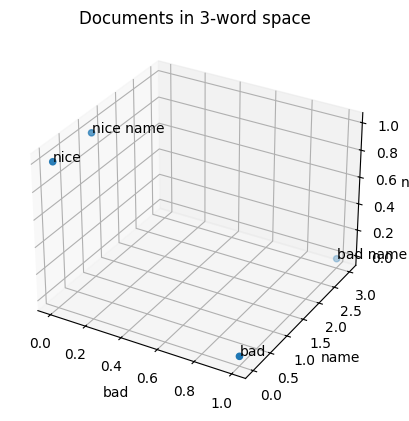

In [27]:
import matplotlib.pyplot as plt

fig = plt.figure()
ax = fig.add_subplot(111, projection="3d")

ax.scatter(X[:, 0], X[:, 1], X[:, 2])

for i, text in enumerate(texts):
    ax.text(X[i, 0], X[i, 1], X[i, 2], f"{text}")

ax.set_xlabel("bad")
ax.set_ylabel("name")
ax.set_zlabel("nice")
ax.set_title("Documents in 3-word space")
plt.show()

In [28]:
# Dot products: word similarities based on co-occurrence in documents
X.T @ X

array([[ 2,  3,  0],
       [ 3, 10,  1],
       [ 0,  1,  2]])

## Similarities (dot products) and correlations between word vectors

Look at the matrix $X^\top X$ in the previous code cell. The diagonal elements of this matrix are squared lengths of the word vectors. The word "name" occurs four times in the corpus, once in the second document and three times in the third. Its word vector is $(0, 1, 3, 0)$ and its squared length is

$$
(0, 1, 3, 0) \cdot (0, 1, 3, 0) = 0^2 + 1^2 + 3^2 + 0^2 = 10
$$

The words "bad" and "name" occur together in the third document, so their dot product is

$$
(1, 0, 1, 0) \cdot (0, 1, 3, 0) = 1*0 + 0*1 + 1*3 + 0*0 = 3
$$

and they are more similar to each other than "bad" and "nice", which don't occur in the same document anywhere and have a zero dot product (are orthogonal to each other):

$$
(1, 0, 1, 0) \cdot (0, 1, 0, 1) = 1*0 + 0*1 + 1*0 + 0*1 = 0
$$

Note that $X^\top X$ is simply a matrix of dot products between every pair of word vectors. You are already familiar with the covariance matrix, a matrix with elements:

$$
\frac{1}{N} \sum_{k=1}^N (x_{ki} - \bar{x}_i)(x_{kj} - \bar{x}_j)
$$

In fact, centering every column of $X$ to zero mean and taking $X^\top X$ after that is equivalent to computing the covariance matrix (up to the factor $1/N$).

In [29]:
X1 = (X - X.mean(axis=0))
X1

array([[ 0.5, -1. , -0.5],
       [-0.5,  0. ,  0.5],
       [ 0.5,  2. , -0.5],
       [-0.5, -1. ,  0.5]])

In [30]:
X1.T @ X1 / (X1.shape[0])

array([[ 0.25,  0.25, -0.25],
       [ 0.25,  1.5 , -0.25],
       [-0.25, -0.25,  0.25]])

In [31]:
np.cov(X, rowvar=False, ddof=0)

array([[ 0.25,  0.25, -0.25],
       [ 0.25,  1.5 , -0.25],
       [-0.25, -0.25,  0.25]])

Furthermore, if you scale each column of $X$ to unit variance, 
then $X^\top X$ is (up to a constant factor) the correlation matrix.

In [32]:
X2 = (X - X.mean(axis=0)) / X.std(axis=0)
X2

array([[ 1.        , -0.81649658, -1.        ],
       [-1.        ,  0.        ,  1.        ],
       [ 1.        ,  1.63299316, -1.        ],
       [-1.        , -0.81649658,  1.        ]])

In [33]:
X2.T @ X2

array([[ 4.        ,  1.63299316, -4.        ],
       [ 1.63299316,  4.        , -1.63299316],
       [-4.        , -1.63299316,  4.        ]])

In [34]:
X2.T @ X2 / X.shape[0]

array([[ 1.        ,  0.40824829, -1.        ],
       [ 0.40824829,  1.        , -0.40824829],
       [-1.        , -0.40824829,  1.        ]])

In [35]:
np.corrcoef(X, rowvar=False)

array([[ 1.        ,  0.40824829, -1.        ],
       [ 0.40824829,  1.        , -0.40824829],
       [-1.        , -0.40824829,  1.        ]])

## Eigenvalues and eigenvectors of word similarities

Let's compute the eigenvalues and eigenvectors of $X^\top X$ to examine how they relate to the word vectors. Note that the eigenvectors are direction (weightings of words) in word space.

In [36]:
def compute_eigen(X):
    eigenvalues, eigenvectors = np.linalg.eigh(X.T @ X)
    order = np.argsort(eigenvalues)[::-1]
    eigenvalues = eigenvalues[order]
    eigenvectors = eigenvectors[:, order]

    print("Eigenvalues:")
    print(eigenvalues.round(2))
    print("\nEigenvectors:")
    print(eigenvectors.round(2))

    return eigenvalues, eigenvectors

eigenvalues, eigenvectors = compute_eigen(X)

Eigenvalues:
[11.1  2.   0.9]

Eigenvectors:
[[ 0.31 -0.32  0.9 ]
 [ 0.94 -0.   -0.33]
 [ 0.1   0.95  0.3 ]]


The first eigenvector has positive weights for all words, highest for "name" and lowest for "nice". It gives the direction of highest variance in word space and because the word vectors have different lengths, the first eigenvector is dominated by the word "name" which has the largest length (occurs most often in the corpus). We can interpret it as a "popularity" direction in word space.

You may wonder why the last weight (for the word "nice") in the first eigenvector is smallest although "bad" and "nice" occur in the same number of documents. This is because the first eigenvector points to the "heaviest" word and distributes the weights of the rest according to their similarity to the heaviest word.

"bad" and "nice" both occur in two documents and have the same squared length (2), yet the first eigenvector gives "nice" about a third of the weight of "bad". The first eigenvector does not measure how common a word is. It weights a word by its similarity to the dominant word "name".

$$
X^\top X = \begin{pmatrix} 2 & 3 & 0 \\ 3 & 10 & 1 \\ 0 & 1 & 2 \end{pmatrix}.
$$

The two words differ in their overlap with "name":

- $\text{bad} \cdot \text{name} = 3$: they share document 3, where "name" occurs three times.
- $\text{nice} \cdot \text{name} = 1$: they share document 2, where "name" occurs once.
- $\text{bad} \cdot \text{nice} = 0$: they never occur together.

Write out the eigenvalue equation $X^\top X v = \lambda v$ for the "bad" and "nice" rows:

$$
\lambda v_{\text{bad}} = 2 v_{\text{bad}} + 3 v_{\text{name}} \;\Rightarrow\; v_{\text{bad}} = \frac{3\, v_{\text{name}}}{\lambda - 2},
\qquad
\lambda v_{\text{nice}} = v_{\text{name}} + 2 v_{\text{nice}} \;\Rightarrow\; v_{\text{nice}} = \frac{1\, v_{\text{name}}}{\lambda - 2}.
$$

The denominator $\lambda - 2$ is the same for both words, so $v_{\text{bad}} = 3\, v_{\text{nice}}$ exactly. The factor 3 is the ratio of the two dot products with "name".

"name" gets the largest weight because it has the largest diagonal entry (10): it occurs four times, three of them in one document. The first eigenvector points towards the heaviest and best connected word, and every other word is weighted by its connection to it. All weights are positive because $X^\top X$ has non-negative entries (Perron-Frobenius theorem).

In [37]:
# Check the relations derived above (signs of eigenvectors are arbitrary, so look at ratios)
v_bad, v_name, v_nice = eigenvectors[:, 0]
lambda_1 = eigenvalues[0]

print("v_bad / v_nice:", round(v_bad / v_nice, 4))
print("v_nice / v_name:", round(v_nice / v_name, 4), " 1 / (lambda - 2):", round(1 / (lambda_1 - 2), 4))

v_bad / v_nice: 3.0
v_nice / v_name: 0.1099  1 / (lambda - 2): 0.1099


One way to remove the effect of word frequency would be to scale every word vector to unit length. Compare the eigenvectors of the scaled and unscaled word vectors. The first eigenvector is no longer dominated by the word "name" and has roughly equal weights for "name" and "bad" (0.71 and 0.67), while "nice" still gets a much smaller weight (0.22). 

What we have computed here is called the cosine similarity between the pairs of vectors. The cosine similarity is the dot product of two vectors divided by the product of their lengths. It measures the cosine of the angle between the two vectors. Cosine equal to 1 means the two vectors are in the same direction, cosine equal to -1 means they are in opposite directions, and cosine equal to 0 means they are orthogonal (perpendicular) to each other.

$$
\cos(\theta) = \frac{v_1 \cdot v_2}{\|v_1\| \|v_2\|}
$$

However, the first eigenvector is still not a contrast between words. This is due to the fact that the word vectors have a non-zero level (mean). We can remove this by centering the word vectors to zero mean before normalizing the length.

In [38]:
X.mean(axis=0)

array([0.5, 1. , 0.5])

In [39]:
X_unit = X / np.linalg.norm(X, axis=0)  # every column (word vector) has length 1

eigenvalues_u, eigenvectors_u = compute_eigen(X_unit)

Eigenvalues:
[1.71 1.   0.29]

Eigenvectors:
[[ 0.67 -0.32  0.67]
 [ 0.71 -0.   -0.71]
 [ 0.22  0.95  0.22]]


In [40]:
X_centered = X - X.mean(axis=0)
X_corr = X_centered / np.linalg.norm(X_centered, axis=0)

eigenvalues_c_scaled, eigenvectors_c_scaled = compute_eigen(X_corr)

Eigenvalues:
[ 2.26  0.74 -0.  ]

Eigenvectors:
[[-0.64 -0.29 -0.71]
 [-0.42  0.91  0.  ]
 [ 0.64  0.29 -0.71]]


## Scoring a document against a direction in word space

Although most documents share at least a basic vocabulary (especially words like "the", "a", "and", etc.) we expect documents focusing on a topic like "vascular health" make heavier use of words like "blood", "pressure", "heart", etc. than documents about "linear algebra" which will use words like "matrix", "vector", "eigenvalue", etc. more often.

We can think of a "topic" as a direction in word space. For example $v = (0.5, -0.5, 1)$ would describe a topic somewhat related to "bad", avoids the word "name" and favors the word "nice". We may wonder how close a document is to this or some other topic and fortunately we already have the instrument to measure closeness (similarity) as a document is nothing more than a point (vector) in word space.

For example, the first document $d_1 = (1, 0, 0)$ has a dot product of

$$
d_1 \cdot v = 1*0.5 + 0*(-0.5) + 0*1 = 0.5
$$

to our topic vector $v$.

We can score all documents against a topic in one fell swoop by multiplying the document matrix $X$ by the topic vector $v$ as the result is simply a column vector of dot products:

$$
\begin{pmatrix} 1 & 0 & 0 \\ 0 & 1 & 1 \\ 1 & 3 & 0 \\ 0 & 0 & 1 \end{pmatrix} \begin{pmatrix} 0.5 \\ -0.5 \\ 1 \end{pmatrix} =
\begin{pmatrix} 0.5 \\ 0.5 \\ -1 \\ 1 \end{pmatrix}
$$

Unsurprisingly, the fourth document scores highest against
the topic, because it contains only "nice".

In [41]:
v = np.array([0.5, -0.5, 1])

X @ v

array([ 0.5,  0.5, -1. ,  1. ])

Now we can ask an interesting question: what is the topic with the highest score over all documents? Before we can continue we must first adapt the question because dot-products are not scale-invariant and multiplying a topic by a number will not change the direction (the topic) but can make the score arbitrarily large. We will restrict the comparison to topics of unit length. 


## The first eigenvector and maximal topic score

The eigenvalue decomposition of $X^\top X$ results in a set of eigenvectors $v_1, v_2, \ldots, v_n$ that are orthogonal to each other and have unit length. We have as many vectors as there are words in the vocabulary (dimension of the word space) so we can express any document as a linear combination of these eigenvectors. Let's take any vector $w$ in word space. We can express it by taking a part ($c_i$) of each eigenvector $v_i$ and adding them up:

$$
w = \sum_{i=1}^n c_i v_i
$$

The squared length of $w$ is

$$
\|w\|^2 = w^\top w = \sum_{i=1}^n c_i v_i \cdot \sum_{j=1}^n c_j v_j = \sum_{i=1}^n \sum_{j=1}^n c_i c_j v_i \cdot v_j
$$

We want to restrict $w$ to unit length and here we can see that this requirement boils down to ensuring that the sum of the squares of the coefficients $c_i$ is equal to 1:

$$
\sum_{i=1}^n c_i^2 = 1
$$

Now look at the total score of all documents against $w$ ($Xw$).

$$
||Xw||^2 = (Xw)^\top (Xw)
$$

We apply the LIVE EVIL rule to the transpose and we get

$$
||Xw||^2 = w^\top X^\top X w
$$

We want to compare the total score of all documents against $w$ to the total score of all documents against the first eigenvector $v_1$. For this we will need to express $w$ in terms of the eigenvectors $v_i$ and express the $X^\top X$ in terms of the eigenvalues $\lambda_i$ and eigenvectors $v_i$. First we substitute the expression for $w$ in terms of the eigenvectors:

$$
w^\top X^\top X w = \left(\sum_{i=1}^n c_i v_i\right)^\top X^\top X \left(\sum_{j=1}^n c_j v_j\right)
$$

Now look at the sum on the right. It is multiplied by $X^\top X$ and Matrix multiplication is distributive (we can multiply each term in the sum by $X^\top X$ and add the results). This is quite useful because the eigenvectors have the property that $X^\top X v_i = \lambda_i v_i$.

$$
\begin{align*}
w^\top X^\top X w & = \left(\sum_{i=1}^n c_i v_i\right)^\top \left(\sum_{j=1}^n c_j X^\top X v_j\right) \\
& = \left(\sum_{i=1}^n c_i v_i\right)^\top \left(\sum_{j=1}^n c_j \lambda_j v_j\right) \\
& = \left(\sum_{i=1}^n c_i v_i^\top\right) \left(\sum_{j=1}^n c_j \lambda_j v_j\right)
\end{align*}
$$



The last step brings the transpose inside the sum. This is legal because the transpose of a sum is the sum of the transposes (prove this as an exercise). Now we have the product of two sums which for two terms in each sum expands as

$$
(c_1v_1^\top + c_2v_2^\top)(c_1\lambda_1v_1 + c_2\lambda_2 v_2) = c_1^2 \lambda_1 v_1^\top v_1 + c_1c_2 \lambda_2 v_1^\top v_2 + c_2c_1 \lambda_1 v_2^\top v_1 + c_2^2 \lambda_2 v_2^\top v_2
$$ 

In the more general case we can write the product as a double sum:

$$
\sum_{i=1}^n \sum_{j=1}^n c_i c_j \lambda_j v_i^\top v_j
$$

This sum is actually simpler that it looks because the eigenvectors are orthogonal so the dot products ($v_i^\top v_j$) are zero for $i \neq j$. Their length is 1, meaning that the dot products of matching indices $v_i^\top v_i$ equal one. Because of this, we can drop the double sum (the cross-product terms are zero):

$$
w^\top X^\top X w = \sum_{i=1}^n c_i^2 \lambda_i
$$

From here it is easy to see this sum has an upper bound. This is due to the fact that the eigenvalues can be ordered from largest to smallest and are all non-negative: $\lambda_1 \geq \lambda_2 \geq \ldots \geq \lambda_n \geq 0$.

$$
w^\top X^\top X w = \sum_{i=1}^n c_i^2 \lambda_i \leq \sum_{i=1}^n c_i^2 \lambda_1 = \lambda_1 \sum_{i=1}^n c_i^2 = \lambda_1
$$


$$
v_1^\top X^\top X v_1 = \sum_{i=1}^n c_i^2 \lambda_i = \lambda_1
$$

The conclusion from the above expression is that any topic will have a total score against all documents that is less than or equal to the first eigenvalue. We can attain this upper bound by choosing $c_1 = 1, c_{i\neq 1} = 0$ so that

$$
w = 1 v_1 + 0 v_2 + \ldots + 0 v_n = v_1
$$

and the total score of all documents against the first eigenvector is equal to the first eigenvalue:

$$
\|Xv_1\|^2 = v_1^\top X^\top X v_1 = \lambda_1 .
$$


At this point you may wonder whether there are other directions in word space that also attain the upper bound. This is a question of uniqueness and the answer is yes, it is unique (up  to a direction). This is also a nice question to explore as an exercise (you should do it).

## Second singular value/vector

Until now we have established that the first eigenvector of $X^\top X$ points in the direction of the largest score (similarity with the topic) $Xv_1$. What about the second eigenvector $v_2$? Consider a topic $w$ that is orthogonal (unrelated) to the first eigenvector $v_1$ and has unit length. What is the direction that maximizes the total score of all documents against $w$?  Let's write our question compactly as a maximization problem:

$$
\underset{||w|| = 1, w \perp v_1}{\max} ||Xw||^2
$$

First, let's look at $w$ in its basis representation in terms of the eigenvectors $v_i$:

$$
w = \sum_{i=1}^n c_i v_i
$$

The coefficients $c_i$ are the weights of the eigenvectors in the linear combination. These are the projections of $w$ onto the eigenvectors $v_i$ or in other words the coordinates of $w$ in the basis of eigenvectors so we can write them as

$$
c_i = w \cdot v_i
$$

We should see that $c_1$ must be zero because we require $w$ to be orthogonal to $v_1$ so that $w \cdot v_1 = 0$. We have one more requirement that $w$ must have unit length. This means that the sum of the squares of the coefficients must be equal to 1:

$$
||w||^2 = \sum_{i=1}^n c_i^2 = 1
$$

Now let's turn to the score that we want to maximize.

$$
||Xw||^2 = w^\top X^\top X w
$$




The first part of the expression is the transpose of $w$ and we can substitute with its basis representation starting with the left side:

$$
X^\top X w  = X^\top X \sum_{i=2}^n c_i v_i = \sum_{i=2}^n c_i X^\top X v_i = \sum_{i=2}^n c_i \lambda_i v_i
$$

The last step follows from the property of eigenvectors that $X^\top X v_i = \lambda_i v_i$.
To get the full expression for the score multiply the above by $w^\top$:

$$
w^\top X^\top X w = \left(\sum_{i=2}^n c_i v_i\right)^\top \left(\sum_{j=2}^n c_j \lambda_j v_j\right) = \sum_{i=2}^n c_i^2 \lambda_i
$$

The last transformation follows the same logic as in the previous section and the bound is obtained by considering the largest eigenvalue in the sum (finish this as an exercise).

In [42]:
E = np.array([[1, -1], [1, 1]]) / np.sqrt(2)
print(E)

A = E @ np.diag([2, 1]) @ E.T
A

[[ 0.70710678 -0.70710678]
 [ 0.70710678  0.70710678]]


array([[1.5, 0.5],
       [0.5, 1.5]])

## Singular Layers

The usual approach to teaching matrix multiplication in undergraduate courses focuses on the computational mechanics using the row-by-column rule (dot products).

$$
\begin{align*}
\begin{pmatrix} a & b \\ c & d \end{pmatrix} \begin{pmatrix} e & f \\ g & h \end{pmatrix} & = \begin{pmatrix}
\begin{pmatrix} a & b \end{pmatrix} \begin{pmatrix} e \\ g \end{pmatrix} & \begin{pmatrix} a & b \end{pmatrix} \begin{pmatrix} f \\ h \end{pmatrix} \\
\begin{pmatrix} c & d \end{pmatrix} \begin{pmatrix} e \\ g \end{pmatrix} & \begin{pmatrix} c & d \end{pmatrix} \begin{pmatrix} f \\ h \end{pmatrix}
\end{pmatrix} \\
& = \begin{pmatrix} ae + bg & af + bh \\ ce + dg & cf + dh \end{pmatrix}
\end{align*}
$$

Another (and often much more useful) way to think about matrix multiplication is a weighting of the columns of the first matrix by the columns of the second matrix:

$$
\begin{align*}
\begin{pmatrix} a & b \\ c & d \end{pmatrix} \begin{pmatrix} e & f \\ g & h \end{pmatrix} & = \begin{pmatrix}e \begin{pmatrix} a \\ c \end{pmatrix} + g \begin{pmatrix} b \\ d \end{pmatrix}, \quad f \begin{pmatrix} a \\ c \end{pmatrix} + h \begin{pmatrix} b \\ d \end{pmatrix} \end{pmatrix} \\
& = \begin{pmatrix} ae + bg & af + bh \\ ce + dg & cf + dh \end{pmatrix}
\end{align*}
$$

A third way to view matrix multiplication is as a sum of outer products of the columns of the first matrix and the rows of the second matrix:

$$
\begin{align*}
\begin{pmatrix} a & b \\ c & d \end{pmatrix} \begin{pmatrix} e & f \\ g & h \end{pmatrix} & = \begin{pmatrix} a \\ c \end{pmatrix} \begin{pmatrix} e & f \end{pmatrix} + \begin{pmatrix} b \\ d \end{pmatrix} \begin{pmatrix} g & h \end{pmatrix} \\
& = \begin{pmatrix} ae & af \\ ce & cf \end{pmatrix} + \begin{pmatrix} bg & bh \\ dg & dh \end{pmatrix} \\
& = \begin{pmatrix} ae + bg & af + bh \\ ce + dg & cf + dh \end{pmatrix}
\end{align*}
$$

This third way is particularly useful for understanding the singular value decomposition and lower rank approximations.

The eigenvalue and singular value decompositions express a matrix as a multiple of three matrices: $U$, $\Sigma$, and $V^\top$. Let's focus on the first and last matrix (the $\Sigma$ matrix is diagonal and only scales the columns of $U$ and $V^\top$).

$$
U \Sigma V^\top = \begin{pmatrix} u_1 & u_2 & u_3 \end{pmatrix} \begin{pmatrix} \sigma_1 & 0 & 0 \\ 0 & \sigma_2 & 0 \\ 0 & 0 & \sigma_3 \end{pmatrix} \begin{pmatrix} v_1^\top \\ v_2^\top \\ v_3^\top \end{pmatrix} = \sigma_1 u_1 v_1^\top + \sigma_2 u_2 v_2^\top + \sigma_3 u_3 v_3^\top
$$

In the more general case, we can write with $r$ singular values and vectors:

$$
U \Sigma V^\top = \sum_{i=1}^r \sigma_i u_i v_i^\top
$$

The sum in the last expression is something very interesting. It shows us how to build up the original matrix $X$ by adding together matrices (layers) of rank 1. The layers are ordered by importance (their contribution to the X matrix) and the singular
values are the importance weights.

In [43]:
# Reduced SVD: X = U @ diag(singular_values) @ Vt
U, singular_values, Vt = np.linalg.svd(X, full_matrices=False)

# Reconstruct X using the first 1, 2, and 3 singular components

rank = 3

X_rank = (U[:, :rank] * singular_values[:rank]) @ Vt[:rank, :]
print(f"\nRank-{rank} approximation:")
print(X_rank.round(2))


Rank-3 approximation:
[[ 1. -0.  0.]
 [ 0.  1.  1.]
 [ 1.  3.  0.]
 [-0.  0.  1.]]


## Image example: building a picture from layers

A very nice visualization of the singular layers is to take a grayscale image and try to reconstruct it from the singular layers.  A grayscale image is just a matrix of pixel intensities (from 0: black to 255: white), so the same decomposition applies. Here, $n$ = image height and $m$ = image width.

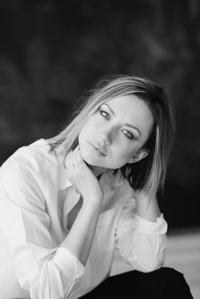

In [1]:
from PIL import Image
import requests
from io import BytesIO
import numpy as np

url = "https://raw.githubusercontent.com/febse/data/refs/heads/main/ta/example_photo.jpg"
response = requests.get(url)
img = Image.open(BytesIO(response.content)).convert("L")
img = img.resize((200, int(img.height * 200 / img.width)))
display(img)

In [3]:
img_matrix = np.array(img)
print("Image matrix shape:", img_matrix.shape)

U_img, S_img, VT_img = np.linalg.svd(img_matrix, full_matrices=False)
print("U:", U_img.shape, " S:", S_img.shape, " V^T:", VT_img.shape)

print(img_matrix[:5, :5])  # Display a small portion of the image matrix for verification

Image matrix shape: (299, 200)
U: (299, 200)  S: (200,)  V^T: (200, 200)
[[24 26 25 24 25]
 [25 25 27 26 24]
 [24 25 24 25 24]
 [25 26 26 24 25]
 [23 25 25 24 26]]


In [4]:
def show_reconstructed_image(start_layer, end_layer, U, S, VT):
    if not 0 <= start_layer < end_layer <= len(S):
        raise ValueError(f"Expected 0 <= start_layer < end_layer <= {len(S)}")

    # Display the first singular layer in the selected range
    first_layer = S[start_layer] * np.outer(U[:, start_layer], VT[start_layer, :])
    first_layer_uint8 = np.clip(first_layer, 0, 255).astype(np.uint8)
    first_layer_pil = Image.fromarray(first_layer_uint8)

    # Reconstruct the image from the selected layers [start_layer, end_layer)
    range_reconstruction = U[:, start_layer:end_layer] @ np.diag(S[start_layer:end_layer]) @ VT[start_layer:end_layer, :]

    range_uint8 = np.clip(range_reconstruction, 0, 255).astype(np.uint8)
    range_pil = Image.fromarray(range_uint8)

    # Show both images side by side for comparison
    combined_width = first_layer_pil.width + range_pil.width
    combined_height = max(first_layer_pil.height, range_pil.height)
    combined_image = Image.new('L', (combined_width, combined_height))
    combined_image.paste(first_layer_pil, (0, 0))
    combined_image.paste(range_pil, (first_layer_pil.width, 0))
    
    return combined_image.resize((800, int(combined_image.height * 800 / combined_image.width)))

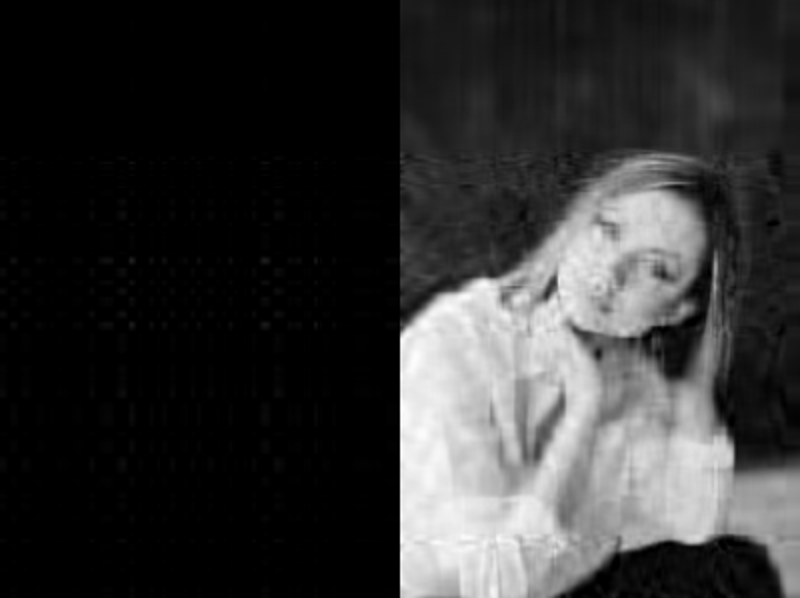

In [8]:
# Left: the first singular layer in the range. Right: the reconstruction from the range.
# The start layer is included and the end layer is excluded (Python slice convention).
start_layer = 20
end_layer = 30

display(show_reconstructed_image(start_layer, end_layer, U_img, S_img, VT_img))